In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings

# Scikit-Learn imports
import sklearn
assert sklearn.__version__ >= '1.6'

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, RobustScaler, FunctionTransformer, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline, Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, mean_absolute_error
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

from smartmeter.db import get_engine
connection = get_engine()


# Opdracht 1


We halen het verbruik, injectie en piekdata van alle gebruikers op uit de `FactEnergyUsageMonthly`-tabel, en voegen via een join de kolom `UserType` uit `DimUser` toe.


In [2]:
factEnergyUsageMonthly = pd.read_sql('SELECT Month, MonthlyUsage_kWh, MonthlyInjection_kWh, MonthlyPeak_kW, MonthlyUsageDay_kWh, MonthlyInjectionDay_kWh, MonthlyUsageNight_kWh, MonthlyInjectionNight_kWh, UserType FROM FactEnergyUsageMonthly feum JOIN DimUser du ON feum.Userkey = du.UserKey', connection)
factEnergyUsageMonthly.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28800 entries, 0 to 28799
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Month                      28800 non-null  object 
 1   MonthlyUsage_kWh           28800 non-null  float64
 2   MonthlyInjection_kWh       28800 non-null  float64
 3   MonthlyPeak_kW             28800 non-null  float64
 4   MonthlyUsageDay_kWh        28800 non-null  float64
 5   MonthlyInjectionDay_kWh    28800 non-null  float64
 6   MonthlyUsageNight_kWh      28800 non-null  float64
 7   MonthlyInjectionNight_kWh  28800 non-null  float64
 8   UserType                   28800 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.0+ MB


We veranderen het datatype van de kolom `Month` naar een getal.


In [3]:
factEnergyUsageMonthly['Month'] = factEnergyUsageMonthly['Month'].astype(int)
factEnergyUsageMonthly.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28800 entries, 0 to 28799
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Month                      28800 non-null  int64  
 1   MonthlyUsage_kWh           28800 non-null  float64
 2   MonthlyInjection_kWh       28800 non-null  float64
 3   MonthlyPeak_kW             28800 non-null  float64
 4   MonthlyUsageDay_kWh        28800 non-null  float64
 5   MonthlyInjectionDay_kWh    28800 non-null  float64
 6   MonthlyUsageNight_kWh      28800 non-null  float64
 7   MonthlyInjectionNight_kWh  28800 non-null  float64
 8   UserType                   28800 non-null  object 
dtypes: float64(7), int64(1), object(1)
memory usage: 2.0+ MB


We gaan onze trainingsdata en testdata scheiden.


In [4]:
X = factEnergyUsageMonthly.drop(columns=['UserType'])
y = factEnergyUsageMonthly['UserType']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=factEnergyUsageMonthly[['UserType', 'Month']], test_size=0.2, random_state=42)


We maken een pipeline waarbij we een `StandardScaler` gebruiken voor de numerieke kolommen.


In [5]:
standard_scaler = StandardScaler()

preprocessing = ColumnTransformer(
    transformers=[
        ('num', standard_scaler, X.select_dtypes(include=['number']).columns),
    ],
    remainder='passthrough',
    n_jobs=-1,
)


We gebruiken onze pipeline met aantal verschillende classifier. We gebruiken classifiers omdat we geen waarde moeten verspellen maar wel een klasse.


In [6]:
classifiers = [
    ('DecisionTreeClassifier', DecisionTreeClassifier(random_state=42)),
    ('RandomForestClassifier', RandomForestClassifier(random_state=42, n_jobs=-1)),
    ('GradientBoostingClassifier', GradientBoostingClassifier(random_state=42)),
    ('LogisticRegression', LogisticRegression(random_state=42)),
    ('SVC', SVC(kernel='poly', degree=3, random_state=42)),
]

for name, classifier in classifiers:
    pipeline = make_pipeline(
        preprocessing,
        classifier
    )
    pipeline.fit(X_train, y_train)

    score = cross_val_score(pipeline, X_train, y_train, cv=3, scoring='accuracy').mean()
    print(f'Classifier: {name}, Accuracy: {score:.4f}')


Classifier: DecisionTreeClassifier, Accuracy: 0.5924
Classifier: RandomForestClassifier, Accuracy: 0.6590
Classifier: GradientBoostingClassifier, Accuracy: 0.6696
Classifier: LogisticRegression, Accuracy: 0.6056
Classifier: SVC, Accuracy: 0.5982


We gebruiken de RandomForestClassifier en gaan kijken wat de kwaliteit van het model is.


In [7]:
classifier = RandomForestClassifier(random_state=42)
print(f'Classifier: {classifier}')

pipeline = make_pipeline(
    preprocessing,
    classifier
)
pipeline.fit(X_train, y_train)

score = cross_val_score(pipeline, X_train, y_train, cv=3, scoring='accuracy').mean()
print(f'Train set accuracy: {score:.4f}')

predictions = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f'Test set accuracy: {accuracy:.4f}')


Classifier: RandomForestClassifier(random_state=42)
Train set accuracy: 0.6590
Test set accuracy: 0.6681


Dit basismodel behaalt een nauwkeurigheid van 65.90% op de trainingsdata en 66.81% op de testdata.


---


Om de accuraatheid van onze voorspelling te verbeteren, gaan we een paar features toevoegen. We beginnen met de maand. De meeste modellen kunnen beter trainen met cyclische features als die omgezet worden naar een sinus- en cosinuswaarde.


In [8]:
factEnergyUsageMonthly['Month_sin'] = np.sin(factEnergyUsageMonthly['Month'] * (2 * np.pi / 12))
factEnergyUsageMonthly['Month_cos'] = np.cos(factEnergyUsageMonthly['Month'] * (2 * np.pi / 12))
factEnergyUsageMonthly.drop(columns=['Month'], inplace=True)
factEnergyUsageMonthly.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28800 entries, 0 to 28799
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   MonthlyUsage_kWh           28800 non-null  float64
 1   MonthlyInjection_kWh       28800 non-null  float64
 2   MonthlyPeak_kW             28800 non-null  float64
 3   MonthlyUsageDay_kWh        28800 non-null  float64
 4   MonthlyInjectionDay_kWh    28800 non-null  float64
 5   MonthlyUsageNight_kWh      28800 non-null  float64
 6   MonthlyInjectionNight_kWh  28800 non-null  float64
 7   UserType                   28800 non-null  object 
 8   Month_sin                  28800 non-null  float64
 9   Month_cos                  28800 non-null  float64
dtypes: float64(9), object(1)
memory usage: 2.2+ MB


We voegen ook de feature `hasInjection` toe zodat het modellen makkelijker kan onderscheiden of een gebruiker zonnepanelen heeft of niet.


In [9]:
factEnergyUsageMonthly['hasInjection'] = factEnergyUsageMonthly['MonthlyInjection_kWh'] != 0
factEnergyUsageMonthly['hasInjection'].value_counts()


hasInjection
False    14414
True     14386
Name: count, dtype: int64

We voegen ook een feature toe die het verbruik indeelt in een aantal klassen.


In [10]:
medium = factEnergyUsageMonthly['MonthlyUsage_kWh'].quantile(0.5)
high = factEnergyUsageMonthly['MonthlyUsage_kWh'].quantile(0.7)
very_high = factEnergyUsageMonthly['MonthlyUsage_kWh'].quantile(0.8)
extreme_high = factEnergyUsageMonthly['MonthlyUsage_kWh'].quantile(0.9)

def getUsageClass(row):
    usage = row['MonthlyUsage_kWh']
    if usage <= medium:
        return 'Low'
    if usage <= high:
        return 'Medium'
    if usage <= very_high:
       return 'High'
    if usage <= extreme_high:
        return 'Very High'
    return 'Extremely High'

factEnergyUsageMonthly['UsageClass'] = factEnergyUsageMonthly.apply(getUsageClass, axis=1)
factEnergyUsageMonthly['UsageClass'].value_counts()


UsageClass
Low               14400
Medium             5760
High               2880
Extremely High     2880
Very High          2880
Name: count, dtype: int64

Als laatste feature voegen we de `Usage_Injection_Ratio` toe. Dit toont de verhouding tussen verbruik en injectie.


In [11]:
factEnergyUsageMonthly["Usage_Injection_Ratio"] = factEnergyUsageMonthly["MonthlyUsage_kWh"] / (factEnergyUsageMonthly["MonthlyInjection_kWh"] + 1)
factEnergyUsageMonthly.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28800 entries, 0 to 28799
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   MonthlyUsage_kWh           28800 non-null  float64
 1   MonthlyInjection_kWh       28800 non-null  float64
 2   MonthlyPeak_kW             28800 non-null  float64
 3   MonthlyUsageDay_kWh        28800 non-null  float64
 4   MonthlyInjectionDay_kWh    28800 non-null  float64
 5   MonthlyUsageNight_kWh      28800 non-null  float64
 6   MonthlyInjectionNight_kWh  28800 non-null  float64
 7   UserType                   28800 non-null  object 
 8   Month_sin                  28800 non-null  float64
 9   Month_cos                  28800 non-null  float64
 10  hasInjection               28800 non-null  bool   
 11  UsageClass                 28800 non-null  object 
 12  Usage_Injection_Ratio      28800 non-null  float64
dtypes: bool(1), float64(10), object(2)
memory usag

We gaan nu de data visualiseren om te zien hoe de data verdeeld is.


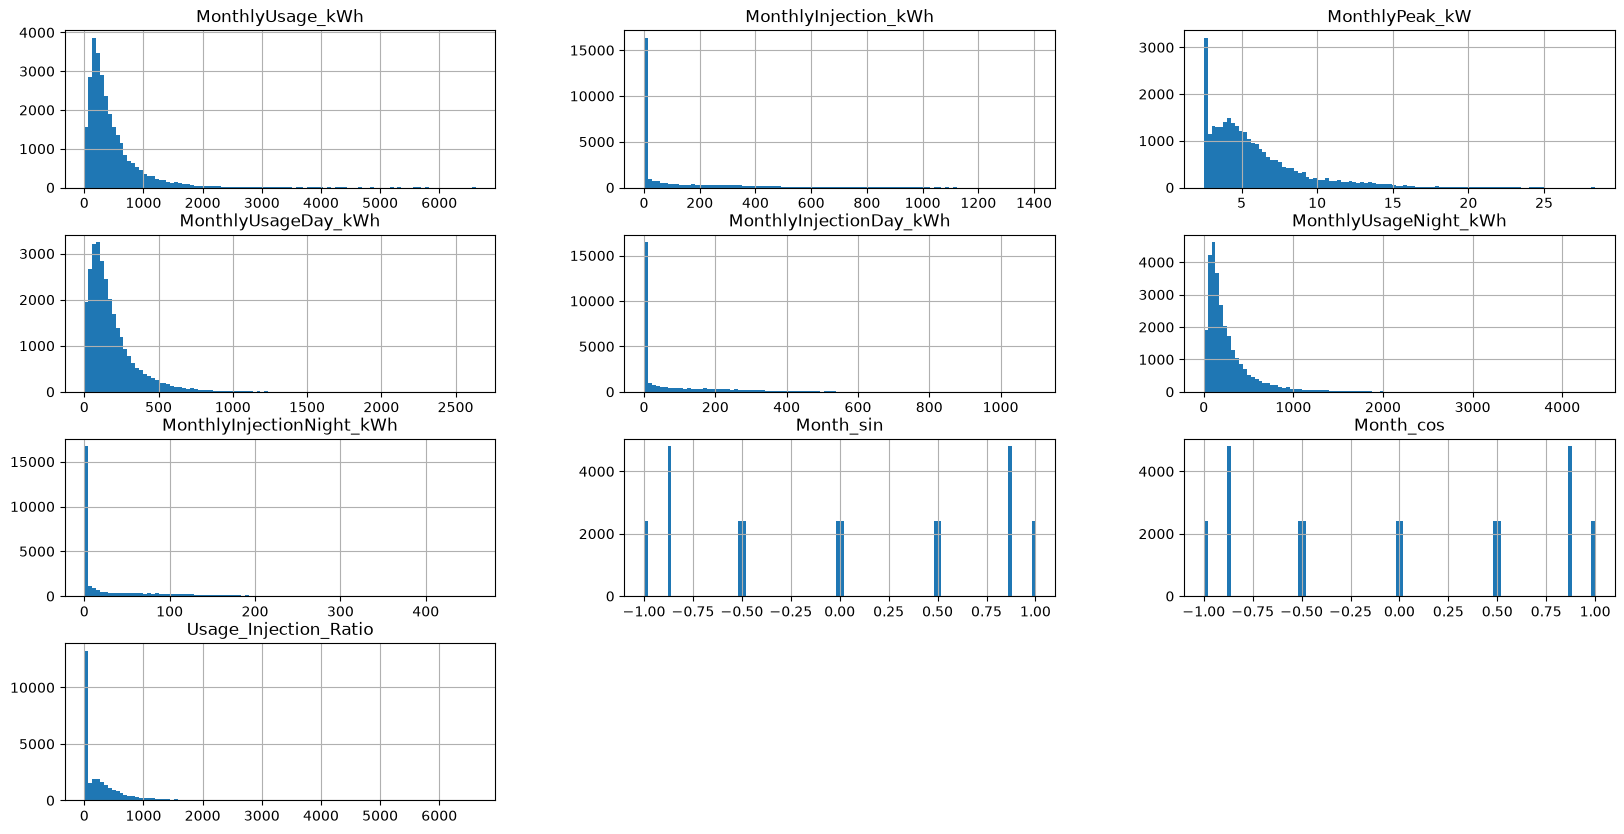

In [12]:
factEnergyUsageMonthly.hist(bins=100, figsize=(20, 10))
plt.show()


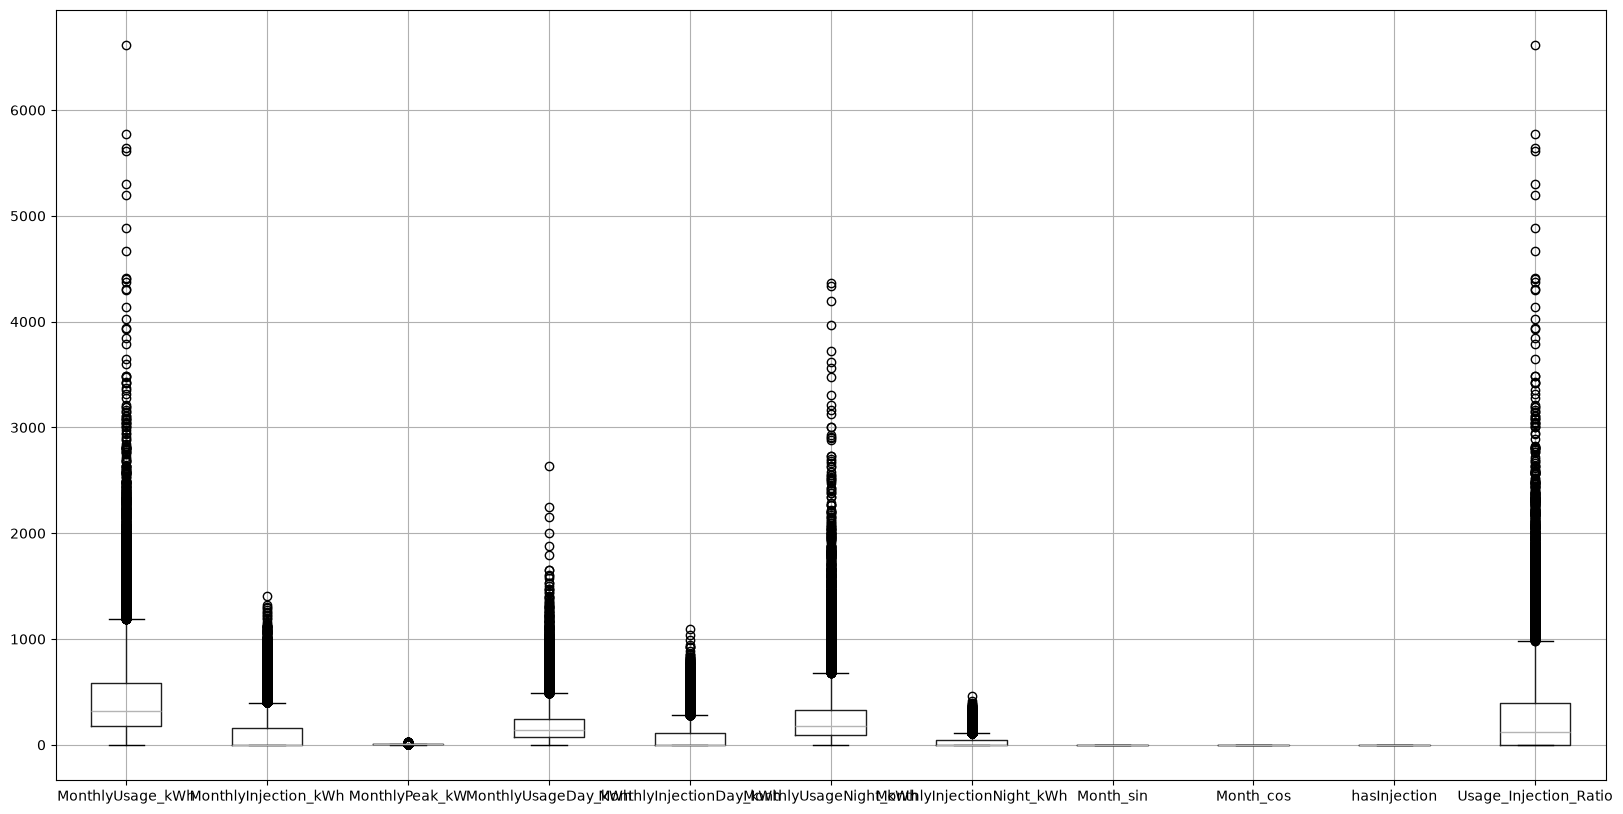

In [13]:
heavy_tailed = ['MonthlyUsage_kWh', 'MonthlyInjection_kWh', 'MonthlyPeak_kW', 'MonthlyUsageDay_kWh', 'MonthlyInjectionDay_kWh', 'MonthlyUsageNight_kWh', 'MonthlyInjectionNight_kWh', 'Usage_Injection_Ratio']
factEnergyUsageMonthly.boxplot(figsize=(20, 10))
plt.show()


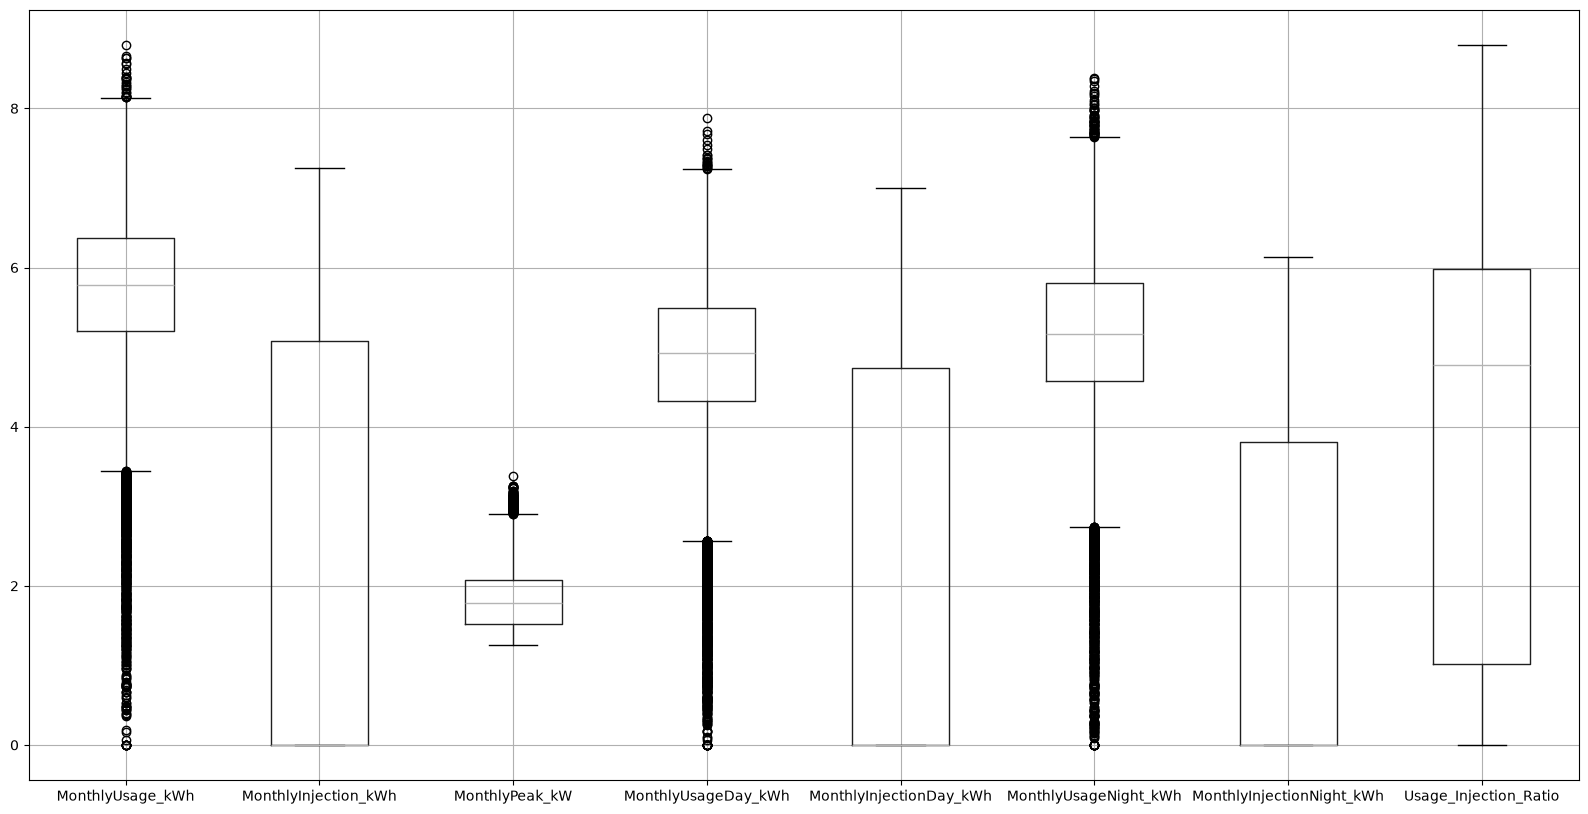

In [14]:
factEnergyUsageMonthly[heavy_tailed].apply(np.log1p).boxplot(figsize=(20, 10))
plt.show()


We maken opnieuw een pipeline waarbij we nu ook onehotencoder gebruiken voor de categorische kolommen.


In [15]:
X = factEnergyUsageMonthly.drop(columns=['UserType'])
y = factEnergyUsageMonthly['UserType']
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=factEnergyUsageMonthly[['UserType', 'Month_sin', 'Month_cos']], test_size=0.2, random_state=42)

standard_scaler = StandardScaler()
robust_scaler = RobustScaler()
log_transformer = FunctionTransformer(np.log1p)
onehot_encoder = OneHotEncoder(handle_unknown='ignore')

preprocessing = ColumnTransformer(
    transformers=[
        ('num', standard_scaler, X.select_dtypes(include=['number']).drop(columns=heavy_tailed).columns),

        ('log_standard', make_pipeline(log_transformer, standard_scaler), ['MonthlyInjection_kWh', 'MonthlyInjectionDay_kWh', 'MonthlyInjectionNight_kWh', 'Usage_Injection_Ratio']),
        ('log_robust', make_pipeline(log_transformer, robust_scaler), ['MonthlyUsage_kWh', 'MonthlyPeak_kW', 'MonthlyUsageDay_kWh', 'MonthlyUsageNight_kWh']),

        ('cat', onehot_encoder, X.select_dtypes(include=['object']).columns),
    ],
    remainder='passthrough',
    n_jobs=-1,
)


We testen onze pipeline opnieuw, maar nu met een paar verschillende classificatiemodellen.


In [16]:
classifiers = [
    ('DecisionTreeClassifier', DecisionTreeClassifier(random_state=42)),
    ('RandomForestClassifier', RandomForestClassifier(random_state=42, n_jobs=-1)),
    ('GradientBoostingClassifier', GradientBoostingClassifier(random_state=42)),
    ('LogisticRegression', LogisticRegression(random_state=42)),
    ('SVC', SVC(kernel='poly', degree=3, random_state=42)),
]

for name, classifier in classifiers:
    pipeline = make_pipeline(
        preprocessing,
        classifier
    )
    pipeline.fit(X_train, y_train)

    score = cross_val_score(pipeline, X_train, y_train, cv=3, scoring='accuracy').mean()
    print(f'Classifier: {name}, Accuracy: {score:.4f}')


Classifier: DecisionTreeClassifier, Accuracy: 0.5947
Classifier: RandomForestClassifier, Accuracy: 0.6648
Classifier: GradientBoostingClassifier, Accuracy: 0.6716
Classifier: LogisticRegression, Accuracy: 0.6496
Classifier: SVC, Accuracy: 0.6640


We nemen de RandomForestClassifier en voeren een gridsearch uit om de parameters te optimaliseren.


In [17]:
classifier = RandomForestClassifier(random_state=42, n_jobs=-1)

pipeline = Pipeline([
    ('prep', preprocessing),
    ('rfc', classifier)
])

param_grid = {
    'rfc__n_estimators': [10, 50, 100],
    'rfc__max_depth': [None, 5, 10],
    'rfc__min_samples_split': [2, 5, 10],
}

grid_search = GridSearchCV(pipeline, param_grid, cv=3, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)
best_model = grid_search.best_estimator_


{'rfc__max_depth': 10, 'rfc__min_samples_split': 10, 'rfc__n_estimators': 100}
0.6758680555555556


We bekijken de nauwkeurigheid van de RandomForestClassifier met de ideale parameters.


In [18]:
classifier = RandomForestClassifier(max_depth=None, min_samples_split=2, n_estimators=50, random_state=42, n_jobs=-1)
print(f'Classifier: {classifier}')

pipeline = make_pipeline(
    preprocessing,
    classifier
)
pipeline.fit(X_train, y_train)

score = cross_val_score(pipeline, X_train, y_train, cv=3, scoring='accuracy').mean()
print(f'Train set accuracy: {score:.4f}')

predictions = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f'Test set accuracy: {accuracy:.4f}')


Classifier: RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=42)
Train set accuracy: 0.6614
Test set accuracy: 0.6590


In de trainingsdata zien we een verbetering in nauwkeurigheid van 65.90% naar 66.14%.

In de testdata zien we een daling in nauwkeurigheid van 66.81% naar 65.90%


# Opdracht 2


We halen de benodigde data op uit de `FactBelpex`-tabel en voegen date en time features toe aan de hand van joins met `DimDate` en `DimTime`.


In [19]:
belpex = pd.read_sql('SELECT fb.*, dd.Year, dd.Month, dd.DayOfMonth, dd.DayOfWeek, dd.DayOfYear, dt.Hour FROM FactBelpex fb JOIN DimDate dd ON fb.DateKey = dd.DateKey JOIN DimTime dt on fb.TimeKey = dt.TimeKey', connection)
belpex.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34124 entries, 0 to 34123
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   DateKey            34124 non-null  int64  
 1   TimeKey            34124 non-null  int64  
 2   BelpexPrice        34124 non-null  float64
 3   Belpex_RLP_MPrice  34124 non-null  float64
 4   Year               34124 non-null  object 
 5   Month              34124 non-null  object 
 6   DayOfMonth         34124 non-null  object 
 7   DayOfWeek          34124 non-null  object 
 8   DayOfYear          34124 non-null  object 
 9   Hour               34124 non-null  object 
dtypes: float64(2), int64(2), object(6)
memory usage: 2.6+ MB


We veranderen het datatype van de tijdgerelateerde kolommen naar een getal.


In [20]:
belpex['Year'] = belpex['Year'].astype(int)
belpex['Month'] = belpex['Month'].astype(int)
belpex['DayOfMonth'] = belpex['DayOfMonth'].astype(int)
belpex['DayOfWeek'] = belpex['DayOfWeek'].astype(int)
belpex['Hour'] = belpex['Hour'].astype(int)
belpex.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34124 entries, 0 to 34123
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   DateKey            34124 non-null  int64  
 1   TimeKey            34124 non-null  int64  
 2   BelpexPrice        34124 non-null  float64
 3   Belpex_RLP_MPrice  34124 non-null  float64
 4   Year               34124 non-null  int64  
 5   Month              34124 non-null  int64  
 6   DayOfMonth         34124 non-null  int64  
 7   DayOfWeek          34124 non-null  int64  
 8   DayOfYear          34124 non-null  object 
 9   Hour               34124 non-null  int64  
dtypes: float64(2), int64(7), object(1)
memory usage: 2.6+ MB


We verwijderen de kolommen die we niet nodig hebben.


In [21]:
belpex.drop(columns=['DateKey', 'TimeKey', 'Belpex_RLP_MPrice'], inplace=True)
belpex.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34124 entries, 0 to 34123
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   BelpexPrice  34124 non-null  float64
 1   Year         34124 non-null  int64  
 2   Month        34124 non-null  int64  
 3   DayOfMonth   34124 non-null  int64  
 4   DayOfWeek    34124 non-null  int64  
 5   DayOfYear    34124 non-null  object 
 6   Hour         34124 non-null  int64  
dtypes: float64(1), int64(5), object(1)
memory usage: 1.8+ MB


We splitsen de data in een trainings- en testset. De data is al gesorteerd op tijd, dus we shuffelen de data niet. Daardoor is de trainingsset de eerste 80% van de data en de testset de laatste 20%.


In [22]:
X = belpex.drop(columns=['BelpexPrice'])
y = belpex['BelpexPrice']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=False)
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)


(27299, 6) (6825, 6) (27299,) (6825,)


We stellen een pipeline op met een `StandardScaler` voor de numerieke kolommen.


In [23]:
standard_scaler = StandardScaler()

preprocessing = ColumnTransformer(
    transformers=[
        ('num', standard_scaler, X.select_dtypes(include=['number']).columns),
    ],
    remainder='passthrough',
    n_jobs=-1,
)


We gebruiken een regressor aangezien we een waarde willen voorspellen. We gebruiken `GradientBoostingRegressor` omdat deze vaak goed presteert op tijdreeksdata. We kijken dan de kwaliteit van het model na de training.


In [24]:
regressor = GradientBoostingRegressor(random_state=42)
print(f'Regressor: {regressor}')

pipeline = make_pipeline(
    preprocessing,
    regressor
)
pipeline.fit(X_train, y_train)

predictions = pipeline.predict(X_test)
mae = -cross_val_score(pipeline, X_train, y_train, cv=3, scoring='neg_mean_absolute_error').mean()
print(f'Train set MAE: {score:.4f}')

predictions = pipeline.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print(f'Test set MAE: {mae:.4f}', end='\n\n')


Regressor: GradientBoostingRegressor(random_state=42)
Train set MAE: 0.6614
Test set MAE: 64.2500



We behalen een MAE van 0.6614 op de trainingsdata en 64.25 op de testdata.
